In [1]:
import sys
import os
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib
import numpy as np
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import pandas as pd
import seaborn as sns
import xarray as xr
import warnings
import iris 
warnings.filterwarnings('ignore')
from pathlib import Path
import dask

In [2]:
from dask.distributed import Client, LocalCluster
#client = Client()


jobfs = os.environ["PBS_JOBFS"]

cluster = LocalCluster(
    n_workers=1,
    threads_per_worker=4,
    memory_limit="18GiB",
    local_directory=jobfs,
)

client = Client(cluster)

In [3]:
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /proxy/8787/status,
Dashboard: /proxy/8787/status,Workers: 1
Total threads: 4,Total memory: 18.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:36597,Workers: 0
Dashboard: /proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:38475,Total threads: 4
Dashboard: /proxy/40665/status,Memory: 18.00 GiB
Nanny: tcp://127.0.0.1:40933,


# ACCESS-AM2 model data

This is where the model data is located/how to open. I've shown you how to open one file at a time and then how to open all of them at once, but selecting for just one variable. 

You can have a go at
- plotting the time average map (see if you can make it 'pretty' - add coast lines, change the colour scheme, add a colour bar, try to put the colour bar on a log scale, etc..)
- Selecting the kunanyi/Mt Wellington grid box (using the lat/lon) and plotting the timeseries/calculating some statistices (mean, standard deviations, 25/75th percentils...)
- Selecting some other variables that might be useful to look at

In [4]:
raw_model_dir = Path('/g/data/q90/ac9768/ACCESS/output/dr943_daily/daily/')
processed_dir = Path('/g/data/jk72/slf563/ACCESS/output/dr943/') # if you prosess your own data - you will need to use your own directory

In [5]:
model_data_test = xr.open_mfdataset(raw_model_dir/'dr943a.pd.sh20160601.nc') # open just one day to get a look at the data and see it in full

In [6]:
model_data_test

<xarray.Dataset> Size: 259MB
Dimensions:                   (time: 1, lat: 73, lon: 192, bnds: 2,
                               model_theta_level_number: 85, pseudo_level: 6,
                               lon_u: 192, lat_v: 74, pressure: 19, time_0: 1)
Coordinates: (12/13)
  * time                      (time) datetime64[ns] 8B 2016-06-01T12:00:00
  * lat                       (lat) float64 584B -89.38 -88.12 ... -0.625 0.625
  * lon                       (lon) float64 2kB 0.9375 2.812 ... 357.2 359.1
  * model_theta_level_number  (model_theta_level_number) int32 340B 1 2 ... 85
    theta_level_height        (model_theta_level_number) float64 680B dask.array<chunksize=(85,), meta=np.ndarray>
    sigma_theta               (model_theta_level_number) float64 680B dask.array<chunksize=(85,), meta=np.ndarray>
    ...                        ...
  * lon_u                     (lon_u) float64 2kB 0.0 1.875 3.75 ... 356.2 358.1
  * lat_v                     (lat_v) float64 592B -90.0 -88.75 ... 0.0 1.25
  * pressure                  (pressure) float64 152B 1e+05 9.25e+04 ... 100.0
  * time_0                    (time_0) datetime64[ns] 8B 2016-06-01T12:20:00....
    height                    float64 8B ...
    height_0                  float64 8B ...
Dimensions without coordinates: bnds
Data variables: (12/123)
    fld_s00i031               (time, lat, lon) float32 56kB dask.array<chunksize=(1, 73, 192), meta=np.ndarray>
    latitude_longitude        int32 4B ...
    time_bnds                 (time, bnds) datetime64[ns] 16B dask.array<chunksize=(1, 2), meta=np.ndarray>
    lat_bnds                  (lat, bnds) float64 1kB dask.array<chunksize=(73, 2), meta=np.ndarray>
    lon_bnds                  (lon, bnds) float64 3kB dask.array<chunksize=(192, 2), meta=np.ndarray>
    fld_s00i049               (time, lat, lon) float32 56kB dask.array<chunksize=(1, 73, 192), meta=np.ndarray>
    ...                        ...
    fld_s38i520               (time, lat, lon) float32 56kB dask.array<chunksize=(1, 73, 192), meta=np.ndarray>
    fld_s38i525               (time, lat, lon) float32 56kB dask.array<chunksize=(1, 73, 192), meta=np.ndarray>
    fld_s38i531               (time, lat, lon) float32 56kB dask.array<chunksize=(1, 73, 192), meta=np.ndarray>
    fld_s38i536               (time, lat, lon) float32 56kB dask.array<chunksize=(1, 73, 192), meta=np.ndarray>
    fld_s38i539               (time, lat, lon) float32 56kB dask.array<chunksize=(1, 73, 192), meta=np.ndarray>
    fld_s50i214               (time, lat, lon) float32 56kB dask.array<chunksize=(1, 73, 192), meta=np.ndarray>
Attributes:
    history:      File dr943a.pd.sh20160601 converted with um2netcdf_iris.py ...
    Conventions:  CF-1.6
    source:       Data from Met Office Unified Model
    um_version:   10.6

# The variables we actually care about
There are too many files to open all the data at once (gadi doesnt like lots of small files). So in the code below we either open pre-exisiting files, or if they don't exisit we create them. 
The files we create are just the one variable per year, significantly reducing the compute resources needed. 

In [7]:
# This just selects the variables we want to look at rather than reading all 123 of them in for the full timeseries. 
variables_to_keep = ['fld_s17i257']
def preprocess(ds):
    return ds['fld_s17i257']

In [8]:
# check if these files exist first, if it does read it in, if it doesnt - generate it. 
f = Path(processed_dir/'dr943a.pd.sh2024_total_dust.nc')
if f.exists():    
    print("File exists, reading in")
    model_data = xr.open_mfdataset(sorted(processed_dir.glob('dr943a.pd.sh20*.nc')), combine='nested', concat_dim='time', chunks={'time': 365},parallel=True) 
else:
    print("File does not exist - will make it") # you will not be able to write to my directory - so if you need to write new files - put them in your working space :) 

    for year in range(2016,2020):
        print('opening', year)
        model_data = xr.open_mfdataset(sorted(raw_model_dir.glob('dr943a.pd.sh{}*.nc'.format(year))), combine='nested', 
                                       concat_dim='time', preprocess=preprocess, chunks={'time': 31},parallel=True)
        print('loading to memory', year)
        model_data_computed = model_data.compute()
        print('writing', year)
        model_data_computed.to_netcdf(processed_dir/'dr943a.pd.sh{}_total_dust.nc'.format(year))

File exists, reading in


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.03/lib/python3.12/site-packages/dask/_task_spec.py:767: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 365. This could degrade performance. Instead, consider rechunking after loading.
  return self.func(*new_argspec, **kwargs)


In [9]:
# Take a look at the data and try to figure out how large it is. 
model_data

<xarray.Dataset> Size: 15GB
Dimensions:                   (time: 3103, model_theta_level_number: 85,
                               lat: 73, lon: 192)
Coordinates:
  * time                      (time) datetime64[ns] 25kB 2016-01-01T12:00:00 ...
  * model_theta_level_number  (model_theta_level_number) int32 340B 1 2 ... 85
    theta_level_height        (model_theta_level_number) float64 680B dask.array<chunksize=(85,), meta=np.ndarray>
    sigma_theta               (model_theta_level_number) float64 680B dask.array<chunksize=(85,), meta=np.ndarray>
  * lat                       (lat) float64 584B -89.38 -88.12 ... -0.625 0.625
  * lon                       (lon) float64 2kB 0.9375 2.812 ... 357.2 359.1
    height                    float64 8B 10.0
    height_0                  float64 8B 1.5
Data variables:
    fld_s17i257               (time, model_theta_level_number, lat, lon) float32 15GB dask.array<chunksize=(365, 22, 19, 48), meta=np.ndarray>

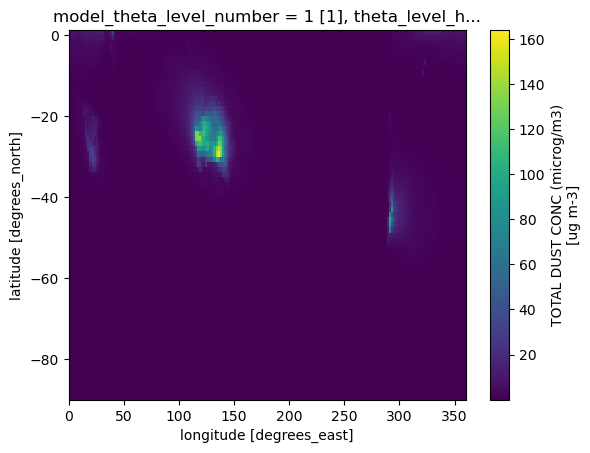

In [10]:
# This line selects just the first model level number, then averages over time and plots. Have a go at making this plot more readable :) 
model_data['fld_s17i257'].sel(model_theta_level_number=1).mean('time').plot()

# Ancillary files that go into the Woodward dust parameterisations 

When you start to explore the parameterisations - you will want to look at what fields are needed for it. Two of fields used in the flux from the surface to the atmsophere are constant 'ancillary' files for the model - they do not change. 

The ancillary files need to be opened with a package called 'iris' and then converted into an xarray data set. You can add some code to plot them/explore them :) 

You might also like to look at what other variables the parameterisations need and see if you can plot them too from the model data. 


In [11]:
fname_vegfrac = '/g/data/access/projects/access/data/ancil/access_cm2_n96e/O1/cable_vegfrac_1850.anc'
# this ancillary file only has one variable - so easy to convert 
cubes = iris.load(fname_vegfrac)
vegfrac =  xr.DataArray.from_iris(cubes[0])


fname_soil_dust = '/g/data/access/projects/access/data/ancil/access_cm2_n96e/O1/qrparm.soil.dust'
# this ancillary has multiple variables so we have to loop over them all to convert them into xarray data sets. 
cubes = iris.load(fname_soil_dust) # open iris cube
cubes_xr = []
for i,cube in enumerate(cubes):  # loop through all cubes and append 
    cubes_xr.append(xr.DataArray.from_iris(cubes[i]))
soil_dust = xr.merge(cubes_xr) # merge them into one dataset 


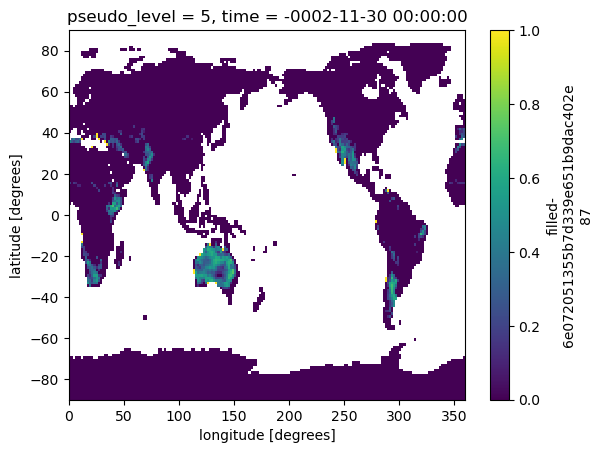

In [12]:
vegfrac.sel(pseudo_level=5).plot() # each psudo level is a differnt plant type... Probably need to figure out what they are at some stage :) 